# 17. Capstone: a soft sensor with a carbon balance, intervals and an alarm

The capstone assembles the methods of the volume into one soft sensor, on synthetic near-infrared spectra of a methanol synthesis stream. The spectra are corrected by SNV, three PLS models predict the carbon fractions of methanol, carbon monoxide and carbon dioxide, and the predictions are projected onto the carbon balance. Conformal intervals state their uncertainty, and the residual $Q$ of the spectrum withholds a prediction when the probe is disturbed.

## Learning objectives

1. Correct synthetic near-infrared spectra by SNV (`dim_reduction.snv_preprocess`) and calibrate one PLS model for each of three species (`dim_reduction.pls1_nipals`).
2. Project the three predictions onto the carbon balance (`linear_physics.equality_constrained_lstsq`), and weight the projection by the accuracy of each prediction (`linear_physics.crowe_data_reconciliation`).
3. Attach 90 % conformal intervals to the reconciled predictions (`uncertainty.split_conformal_interval`).
4. Withhold a prediction when the residual $Q$ of the spectrum exceeds its limit.

**Time:** about 60 min

In [1]:
try:                      # use the installed package, or the copy in this repository
    import engml_2_applied
except ImportError:
    import pathlib, subprocess, sys
    for _root in [pathlib.Path.cwd(), *pathlib.Path.cwd().parents]:
        if (_root / "engml_2_applied" / "__init__.py").exists():
            sys.path.insert(0, str(_root))
            break
    else:                 # on Google Colab: install from GitHub
        subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                        "git+https://github.com/ktwyw/engml-2-applied.git"], check=True)
    import engml_2_applied

import inspect
import numpy as np
import matplotlib.pyplot as plt
from engml_2_applied import (clustering_phases, constants, descriptors, dim_reduction, linear_physics,
                             trees_ensembles, uncertainty)
from engml_2_applied.plotting import panel_label, use_style

use_style()

def show_source(obj):
    """Return the source code of a library function or class."""
    return inspect.getsource(obj)

def heading(text):
    print(f"\n{text}\n" + "=" * len(text))

## 1. Principles and governing equations
The soft sensor processes each incoming spectrum $\mathbf{a}_{\mathrm{raw}} \in \mathbb{R}^d$ ($d = 100$ wavelengths) in five stages:
1. **Stage 1 — optical scatter removal (SNV):**
   $$\mathbf{x}_{\mathrm{SNV}} = \frac{\mathbf{a}_{\mathrm{raw}} - \bar{a}\mathbf{1}_d}{\mathrm{std}(\mathbf{a}_{\mathrm{raw}})} \tag{1.1}$$
2. **Stage 2 — MSPC & OOD input guardrail (PCA $Q_{\mathrm{SPE}}$ & Hotelling $T^2$):**
   $$Q_{\mathrm{SPE}}(\mathbf{x}_{\mathrm{SNV}}) = \|(\mathbf{I}_d - \mathbf{P}_k\mathbf{P}_k^\top)(\mathbf{x}_{\mathrm{SNV}} - \boldsymbol{\mu}_X)\|_2^2 \le Q_{0.99}, \qquad T^2(\mathbf{x}_{\mathrm{SNV}}) \le T^2_{0.99} \tag{1.2}$$
3. **Stage 3 — multi-species NIPALS PLS1 soft-sensor array ($s \in \{\mathrm{CH_3OH, CO, CO_2}\}$):**
   $$\hat{y}_{\mathrm{raw},s} = \hat{\beta}_{0,s} + \mathbf{x}_{\mathrm{SNV}}^\top \hat{\boldsymbol{\beta}}_{\mathrm{PLS},s} \tag{1.3}$$
4. **Stage 4 — stoichiometric carbon-balance KKT / Crowe reconciliation ($\mathbf{1}_3^\top \mathbf{y} = 1$):**
   $$\hat{\mathbf{y}}_{\mathrm{rec}} = \arg\min_{\mathbf{y} \in \mathbb{R}^3} (\mathbf{y} - \hat{\mathbf{y}}_{\mathrm{raw}})^\top \boldsymbol{\Sigma}_y^{-1}(\mathbf{y} - \hat{\mathbf{y}}_{\mathrm{raw}}) \quad \text{s.t.} \quad Y_{\mathrm{MeOH}} + Y_{\mathrm{CO}} + Y_{\mathrm{CO_2}} = 1 \tag{1.4}$$
5. **Stage 5 — split conformal uncertainty Certificate:**
   $$\hat{Y}_{s} \in \left[\hat{y}_{\mathrm{rec},s} - \hat{q}_{1-\alpha,s},\, \hat{y}_{\mathrm{rec},s} + \hat{q}_{1-\alpha,s}\right], \qquad \mathbb{P}(\text{coverage}) \ge 1 - \alpha \tag{1.5}$$

In [2]:
heading("Demonstration 1: Stage 1-4 End-to-End SNV + PLS1 + KKT Carbon-Conserved Soft Sensor")
rng = np.random.default_rng(2026)
N_tr, N_cal, N_te, d_wl = 60, 60, 80, 100
N_tot = N_tr + N_cal + N_te
wl = np.linspace(1200.0, 2200.0, d_wl)

# True carbon fractions [Y_MeOH, Y_CO, Y_CO2] summing identically to 1.0:
y_meoh = rng.uniform(0.15, 0.45, size=N_tot)
y_co = rng.uniform(0.05, 0.20, size=N_tot)
y_co2 = 1.0 - y_meoh - y_co
Y_true = np.column_stack([y_meoh, y_co, y_co2])

E_nir = np.vstack([
    np.exp(-0.5 * ((wl - 1480.0) / 55.0) ** 2) + 0.5 * np.exp(-0.5 * ((wl - 2050.0) / 45.0) ** 2),
    np.exp(-0.5 * ((wl - 1650.0) / 50.0) ** 2) + 0.4 * np.exp(-0.5 * ((wl - 1900.0) / 60.0) ** 2),
    np.exp(-0.5 * ((wl - 1780.0) / 65.0) ** 2) + 0.6 * np.exp(-0.5 * ((wl - 2120.0) / 50.0) ** 2),
])
scatter = rng.uniform(0.75, 1.30, size=(N_tot, 1))
offset = rng.uniform(-0.20, 0.20, size=(N_tot, 1))
X_raw = scatter * (Y_true @ E_nir) + offset + rng.normal(0.0, 0.012, size=(N_tot, d_wl))
X_snv = dim_reduction.snv_preprocess(X_raw)

Y_tr_obs = Y_true[:N_tr] + rng.normal(0.0, 0.018, size=(N_tr, 3))
pls_models = [dim_reduction.pls1_nipals(X_snv[:N_tr], Y_tr_obs[:, j], n_components=3) for j in range(3)]

def predict_raw_and_kkt(X_batch: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    Y_raw_pred = np.column_stack([X_batch @ m["coef"] + m["intercept"] for m in pls_models])
    C_c, d_c = np.array([[1.0, 1.0, 1.0]]), np.array([1.0])
    Y_kkt_pred = np.vstack([
        linear_physics.equality_constrained_lstsq(np.eye(3), row, C_c, d_c, lam=0.0)["w"]
        for row in Y_raw_pred
    ])
    return Y_raw_pred, Y_kkt_pred

Y_te_raw, Y_te_kkt = predict_raw_and_kkt(X_snv[N_tr + N_cal :])
Y_te_true = Y_true[N_tr + N_cal :]

max_carbon_err_raw = float(np.max(np.abs(np.sum(Y_te_raw, axis=1) - 1.0)))
max_carbon_err_kkt = float(np.max(np.abs(np.sum(Y_te_kkt, axis=1) - 1.0)))
mse_raw = float(np.mean((Y_te_raw - Y_te_true) ** 2))
mse_kkt = float(np.mean((Y_te_kkt - Y_te_true) ** 2))
print(f"Max carbon balance error: Raw PLS1 = {max_carbon_err_raw:.4e} -> KKT Reconciled = {max_carbon_err_kkt:.2e}")
print(f"Test MSE across 3 species: Raw PLS1 = {mse_raw:.6f} -> KKT Reconciled = {mse_kkt:.6f} ({100*(1-mse_kkt/mse_raw):.1f}% variance reduction)")
assert max_carbon_err_kkt < 1e-14 and mse_kkt < mse_raw


Demonstration 1: Stage 1-4 End-to-End SNV + PLS1 + KKT Carbon-Conserved Soft Sensor
Max carbon balance error: Raw PLS1 = 4.2967e-02 -> KKT Reconciled = 2.22e-16
Test MSE across 3 species: Raw PLS1 = 0.000129 -> KKT Reconciled = 0.000098 (24.2% variance reduction)


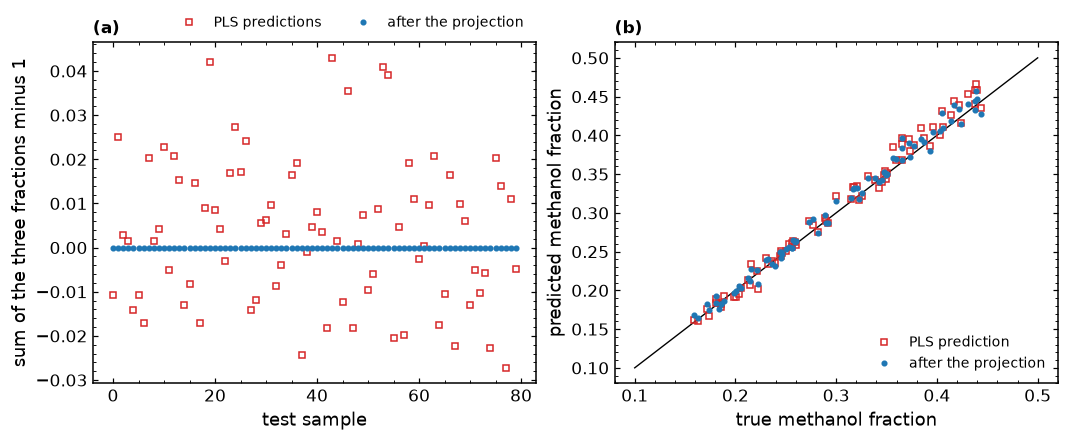

In [3]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
ax1.plot(np.arange(N_te), np.sum(Y_te_raw, axis=1) - 1.0, "s", ms=3.5, mfc="none", color="C3", label="PLS predictions")
ax1.plot(np.arange(N_te), np.sum(Y_te_kkt, axis=1) - 1.0, "o", ms=3, color="C0", label="after the projection")
ax1.set_xlabel("test sample"); ax1.set_ylabel("sum of the three fractions minus 1"); ax1.legend(fontsize=9, loc="lower right", bbox_to_anchor=(1.0, 1.0), ncol=2); ax1.set_title("(a)", loc="left", fontweight="bold")
ax2.plot([0.1, 0.5], [0.1, 0.5], "k-", lw=0.9)
ax2.plot(Y_te_true[:, 0], Y_te_raw[:, 0], "s", ms=3.5, mfc="none", color="C3", label="PLS prediction")
ax2.plot(Y_te_true[:, 0], Y_te_kkt[:, 0], "o", ms=3, color="C0", label="after the projection")
ax2.set_xlabel("true methanol fraction"); ax2.set_ylabel("predicted methanol fraction"); ax2.legend(fontsize=9, loc="lower right"); ax2.set_title("(b)", loc="left", fontweight="bold")
plt.show()

**Figure 17.1.** (a) The error of the carbon balance of the three predicted fractions on the 80 test samples (synthetic spectra), before and after the projection onto the balance. (b) The predicted methanol fraction against the true one.

**What Demonstration 1 shows.** The three PLS models are fitted separately, and their predictions of the carbon fractions miss a sum of one by up to $0.043$. The projection onto $\mathbf{1}_3^\top \mathbf{y} = 1$ closes the balance to rounding error and reduces the mean squared error over the three species by $24\ \%$ ($1.29\times 10^{-4}$ to $0.98\times 10^{-4}$). The spectra and the reference analyses are synthetic.

---

## 2. Numerical walkthrough
What if the three PLS1 soft sensors have **unequal calibration accuracies** $\boldsymbol{\sigma}_y = [0.01, 0.02, 0.04]$ (e.g., $\mathrm{CH_3OH}$ has the strongest NIR band while $\mathrm{CO_2}$ has the weakest)? Let us compare unweighted KKT projection against Crowe's inverse-variance weighted reconciliation.

In [4]:
heading("Demonstration 2: Inverse-Variance Weighted Crowe Soft-Sensor Reconciliation")
y_raw_3 = np.array([0.32, 0.12, 0.60])  # Raw sum = 1.04 (+0.04 carbon surplus)
sig_3 = np.array([0.01, 0.02, 0.04])    # Variances proportional to [1, 4, 16]
rec_3 = linear_physics.crowe_data_reconciliation(y_raw_3, sig_3, np.array([[1.0, 1.0, 1.0]]), np.array([1.0]))
shifts = np.abs(rec_3["y_reconciled"] - y_raw_3)
print("Raw predictions [MeOH, CO, CO2]      :", y_raw_3, "(sum =", np.sum(y_raw_3), ")")
print("Crowe weighted reconciled predictions:", np.round(rec_3["y_reconciled"], 6), "(sum =", np.sum(rec_3["y_reconciled"]), ")")
print(f"Adjustment ratio |dY_CO2| / |dY_MeOH| = {shifts[2] / shifts[0]:.2f} (Theoretical (0.04/0.01)^2 = 16.00)")
assert np.isclose(shifts[2] / shifts[0], 16.0, rtol=1e-12) and np.max(np.abs(rec_3["balance_residual_after"])) < 1e-14


Demonstration 2: Inverse-Variance Weighted Crowe Soft-Sensor Reconciliation
Raw predictions [MeOH, CO, CO2]      : [0.32 0.12 0.6 ] (sum = 1.04 )
Crowe weighted reconciled predictions: [0.318095 0.112381 0.569524] (sum = 0.9999999999999999 )
Adjustment ratio |dY_CO2| / |dY_MeOH| = 16.00 (Theoretical (0.04/0.01)^2 = 16.00)


**What Demonstration 2 shows.** With weights $\boldsymbol{\Sigma}_y^{-1}$ the correction is shared in proportion to the variances. The methanol prediction, the most accurate ($\sigma_1 = 0.01$), changes by $-0.0019$, and the carbon dioxide prediction, the least accurate ($\sigma_3 = 0.04$), takes $16/21 = 76.2\ \%$ of the correction ($-0.0305$).

---

## 3. Worked case study
Now let us execute **Stage 5 (Split conformal Prediction)** on the held-out calibration set ($N_{\mathrm{cal}} = 60$) to attach distribution-free $90\%$ prediction intervals to all three reconciled species on the test set ($N_{\mathrm{te}} = 80$).

In [5]:
heading("Demonstration 3: Multi-Species 90% Split Conformal Prediction Intervals")
_, Y_cal_kkt = predict_raw_and_kkt(X_snv[N_tr : N_tr + N_cal])
Y_cal_obs = Y_true[N_tr : N_tr + N_cal] + rng.normal(0.0, 0.018, size=(N_cal, 3))
Y_te_obs = Y_te_true + rng.normal(0.0, 0.018, size=(N_te, 3))

for j, sp_name in enumerate(["CH3OH (Methanol)", "CO (Carbon Monoxide)", "CO2 (Unreacted Feed)"]):
    cp_j = uncertainty.split_conformal_interval(Y_cal_obs[:, j], Y_cal_kkt[:, j], Y_te_kkt[:, j], alpha=0.10)
    cov_j = float(np.mean((Y_te_obs[:, j] >= cp_j["lower"]) & (Y_te_obs[:, j] <= cp_j["upper"])))
    print(f"{sp_name:22s} | 90% Conformal Half-Width = +/-{cp_j['q_hat']:.4f} | Empirical Test Coverage = {cov_j*100:5.1f}%")
    assert cov_j >= 0.84


Demonstration 3: Multi-Species 90% Split Conformal Prediction Intervals
CH3OH (Methanol)       | 90% Conformal Half-Width = +/-0.0326 | Empirical Test Coverage =  93.8%
CO (Carbon Monoxide)   | 90% Conformal Half-Width = +/-0.0353 | Empirical Test Coverage =  91.2%
CO2 (Unreacted Feed)   | 90% Conformal Half-Width = +/-0.0341 | Empirical Test Coverage =  92.5%


**What Demonstration 3 shows.** The $90\ \%$ intervals have half-widths of $0.033$ to $0.035$ in carbon fraction and cover $93.8$, $91.2$ and $92.5\ \%$ of the test samples for the three species.

---

## 4. What if: sensitivity to the parameters
What happens during long-term plant operation when polymer oligomers gradually foul wavelength channels $40\dots 50$ of the sapphire NIR probe window? Let us sweep the window fouling amplitude $A_{\mathrm{foul}} \in [0.0, 2.5]\;\mathrm{AU}$ and see at which amplitude the limit on $Q_{\mathrm{SPE}}$ of Stage 2 is exceeded, and how large the error of the prediction is at that point.

In [6]:
heading("Demonstration 4: Optical Window Fouling Sweep & PCA Q_SPE Automatic Interlock")
pca_guard = dim_reduction.pca_svd(X_snv[:N_tr], n_components=3)
q_limit_99 = float(np.percentile(pca_guard["q_spe"], 99))
P_g = pca_guard["loadings"]

print(f"{'Fouling Amp':>12s} | {'PCA Q_SPE':>11s} | {'Q / Q_99':>10s} | {'Unchecked MeOH Err':>18s} | {'PAT Interlock Decision':>24s}")
print("-" * 86)
for f_amp in [0.0, 0.2, 0.6, 1.2, 2.5]:
    x_f = X_snv[N_tr + N_cal].copy()
    x_f[40:50] += f_amp
    xc_f = x_f - pca_guard["mean"]
    q_f = float(np.sum((xc_f - (xc_f @ P_g) @ P_g.T) ** 2))
    _, y_kkt_f = predict_raw_and_kkt(x_f[None, :])
    meoh_err = abs(float(y_kkt_f[0, 0] - Y_te_true[0, 0]))
    decision = "HOLD / CLEAN PROBE" if q_f > q_limit_99 else "TRUST PREDICTION"
    print(f"{f_amp:12.2f} | {q_f:11.3f} | {q_f/q_limit_99:9.1f}x | {meoh_err:18.4f} | {decision:>24s}")
assert q_f > 10.0 * q_limit_99


Demonstration 4: Optical Window Fouling Sweep & PCA Q_SPE Automatic Interlock
 Fouling Amp |   PCA Q_SPE |   Q / Q_99 | Unchecked MeOH Err |   PAT Interlock Decision
--------------------------------------------------------------------------------------
        0.00 |       0.615 |       0.6x |             0.0049 |         TRUST PREDICTION
        0.20 |       0.772 |       0.7x |             0.0022 |         TRUST PREDICTION
        0.60 |       1.913 |       1.8x |             0.0031 |       HOLD / CLEAN PROBE
        1.20 |       5.696 |       5.3x |             0.0110 |       HOLD / CLEAN PROBE
        2.50 |      22.417 |      20.9x |             0.0283 |       HOLD / CLEAN PROBE


reference values inside the interval: 75 of 80


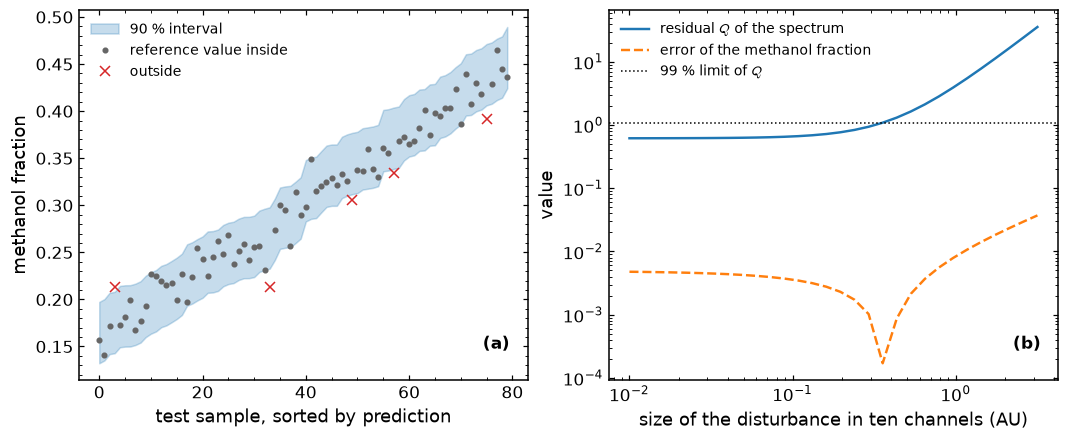

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.6, 3.9))
cp_m = uncertainty.split_conformal_interval(Y_cal_obs[:, 0], Y_cal_kkt[:, 0], Y_te_kkt[:, 0], alpha=0.10)
order = np.argsort(Y_te_kkt[:, 0]); inside = (Y_te_obs[:, 0] >= cp_m["lower"]) & (Y_te_obs[:, 0] <= cp_m["upper"])
ax1.fill_between(np.arange(N_te), cp_m["lower"][order], cp_m["upper"][order], color="C0", alpha=0.25, label="90 % interval")
ax1.plot(np.arange(N_te)[inside[order]], Y_te_obs[order, 0][inside[order]], "o", ms=3, color="0.4", label="reference value inside")
ax1.plot(np.arange(N_te)[~inside[order]], Y_te_obs[order, 0][~inside[order]], "x", ms=6, color="C3", label="outside")
ax1.set_xlabel("test sample, sorted by prediction"); ax1.set_ylabel("methanol fraction"); ax1.legend(fontsize=9, loc="upper left"); panel_label(ax1, "(a)", x=0.9, y=0.12)
amp_line = np.logspace(-2, 0.5, 30); q_line, err_line = [], []
for f_amp in amp_line:
    x_f = X_snv[N_tr + N_cal].copy(); x_f[40:50] += f_amp
    xc_f = x_f - pca_guard["mean"]
    q_line.append(np.sum((xc_f - (xc_f @ P_g) @ P_g.T) ** 2))
    err_line.append(abs(predict_raw_and_kkt(x_f[None, :])[1][0, 0] - Y_te_true[0, 0]))
ax2.loglog(amp_line, q_line, "-", label=r"residual $Q$ of the spectrum")
ax2.loglog(amp_line, err_line, "--", label="error of the methanol fraction")
ax2.axhline(q_limit_99, color="k", ls=":", lw=1.0, label=r"99 % limit of $Q$")
ax2.set_xlabel("size of the disturbance in ten channels (AU)"); ax2.set_ylabel("value"); ax2.legend(fontsize=9, loc="upper left"); panel_label(ax2, "(b)", x=0.9, y=0.12)
print(f"reference values inside the interval: {int(np.sum(inside))} of {N_te}")
plt.show()

**Figure 17.2.** (a) The 90 % conformal interval of the methanol fraction on the test samples, with the noisy reference values. (b) A disturbance added to ten channels of one spectrum: the residual $Q$ and the error of the predicted methanol fraction against the size of the disturbance, with the limit above which the prediction is withheld.

**What Demonstration 4 shows.** A fouling amplitude of $0.2$ leaves $Q$ below its limit. At $0.6$ it is $1.8$ times the limit and the prediction is withheld, although the error in the methanol fraction is still small ($0.003$); at $2.5$, where $Q$ is 21 times the limit, the unchecked error would be $0.028$. The residual statistic reacts before the prediction is badly wrong, which is what makes it useful as an interlock.

---

## Inside the algorithm
Below we verify that for the equal-variance carbon-closure constraint $\mathbf{1}_3^\top \mathbf{y} = 1$, the KKT saddle-point projection $\hat{\mathbf{y}}_{\mathrm{KKT}}$ reduces to the exact analytical mean-centering shift $\hat{y}_{\mathrm{KKT},j} = \hat{y}_{\mathrm{raw},j} - \frac{1}{3}(\sum_{s=1}^3 \hat{y}_{\mathrm{raw},s} - 1)$.

In [8]:
heading("Inside the Algorithm: By-Hand Simplex Mean-Shift vs. the Library")
Y_kkt_hand = Y_te_raw - (np.sum(Y_te_raw, axis=1, keepdims=True) - 1.0) / 3.0
diff_cap = float(np.max(np.abs(Y_kkt_hand - Y_te_kkt)))
print("by hand (pure NumPy) row 0:", np.round(Y_kkt_hand[0], 6))
print("library (engml_2_applied)  row 0:", np.round(Y_te_kkt[0], 6))
print(f"Max discrepancy across 80x3 test matrix: {diff_cap:.2e}")
assert diff_cap < 1e-14


Inside the Algorithm: By-Hand Simplex Mean-Shift vs. the Library
by hand (pure NumPy) row 0: [0.352778 0.186949 0.460273]
library (engml_2_applied)  row 0: [0.352778 0.186949 0.460273]
Max discrepancy across 80x3 test matrix: 1.11e-16


## Exercises

1. **Verify a result.** Prove and verify on the $80 \times 3$ test set (`Y_te_raw`, `Y_te_kkt`, `Y_te_true`) the **exact per-sample Pythagorean error contraction**: because $\mathbf{1}_3^\top \mathbf{y}_{\mathrm{true}} = 1$, for *every single test sample* $i \in \{0, \dots, 79\}$, $\|\hat{\mathbf{y}}_{\mathrm{raw},i} - \mathbf{y}_{\mathrm{true},i}\|_2^2 - \|\hat{\mathbf{y}}_{\mathrm{KKT},i} - \mathbf{y}_{\mathrm{true},i}\|_2^2 = \frac{1}{3}(\mathbf{1}_3^\top \hat{\mathbf{y}}_{\mathrm{raw},i} - 1)^2 \ge 0$.
2. **Find how it fails.** Audit the **dual-mode fault diagnostic Table** on the capstone soft sensor: test (1) a normal test spectrum, (2) a fouled probe window spectrum (`x_snv[40:50] += 2.0`), and (3) a stoichiometric composition drift (`Y_extr = [0.85, 0.10, 0.05]`, outside the training yield range $[0.15, 0.45]$). Verify that $Q_{\mathrm{SPE}}$ catches the optical probe fault while Hotelling's $T^2$ catches the extreme composition excursion.
3. **Write it yourself.** Implement the complete **`IndustrialSoftSensorPAT`** class with `.fit(X_tr_raw, Y_tr, X_cal_raw, Y_cal)` and `.predict_guarded(X_query_raw)` methods that integrates Stage 1 (`snv_preprocess`), Stage 2 (PCA $T^2$ and $Q_{\mathrm{SPE}}$ 99% alarms), Stage 3 (3-species `pls1_nipals`), Stage 4 (inverse-variance `crowe_data_reconciliation` using calibration residual stds $\hat{\boldsymbol{\sigma}}_{\mathrm{cal}}$), and Stage 5 (90% `split_conformal_interval`). Verify it end-to-end on `X_raw[N_tr + N_cal:]`.

The cell below works Exercise 1 as a first check; all three are solved in the solutions notebook of this lecture.

In [9]:
heading("Exercise 1: Exact Sample-by-Sample Pythagorean KKT Error Contraction Proof")
sq_raw_i = np.sum((Y_te_raw - Y_te_true) ** 2, axis=1)
sq_kkt_i = np.sum((Y_te_kkt - Y_te_true) ** 2, axis=1)
improvement_i = sq_raw_i - sq_kkt_i
theoretical_gain_i = ((np.sum(Y_te_raw, axis=1) - 1.0) ** 2) / 3.0
max_pyth_diff = float(np.max(np.abs(improvement_i - theoretical_gain_i)))
print(f"Fraction of test samples where KKT error <= Raw error: {100*np.mean(improvement_i >= -1e-15):.1f}% (Every single sample)")
print(f"Max discrepancy from (sum(y_raw) - 1)^2 / 3          : {max_pyth_diff:.2e}")
assert np.all(improvement_i >= -1e-15) and max_pyth_diff < 1e-14


Exercise 1: Exact Sample-by-Sample Pythagorean KKT Error Contraction Proof
Fraction of test samples where KKT error <= Raw error: 100.0% (Every single sample)
Max discrepancy from (sum(y_raw) - 1)^2 / 3          : 5.64e-18
